<a href="https://colab.research.google.com/github/soundoussouna/cytokine-analysis/blob/main/Tp2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [2]:
conc = np.array([0, 2, 4, 6, 8, 10])                                        # µg/mL
absorbance = 0.0512 * conc + 0.004 + np.random.normal(0, 0.008, conc.size)
absorbance = absorbance.round(3)
pd.DataFrame({"concentration (µg/mL)": conc, "absorbance": absorbance})

,concentration (µg/mL),absorbance
0,0,0.026
1,2,0.111
2,4,0.204
3,6,0.310
4,8,0.404
5,10,0.508


In [3]:
# 1) Droite de régression
pente, ordonnee = np.polyfit(conc, absorbance, 1)
# 2) Coefficient de détermination R²
A_calc = pente * conc + ordonnee                      # absorbance calculée par la droite
ss_res = np.sum((absorbance - A_calc) ** 2)                  # écarts entre mesure et droite
ss_tot = np.sum((absorbance - np.mean(absorbance)) ** 2)            # écarts entre mesure et moyenne
R2 = 1 - ss_res / ss_tot
# 3) Affichage
print(f"pente = {pente:.4f} | ordonnée = {ordonnee:.4f} | R² = {R2:.4f}")

pente = 0.0485 | ordonnée = 0.0180 | R² = 0.9989


Dans la cuvette : 6.02 µg/mL | Solution mère : 30.1 µg/mL


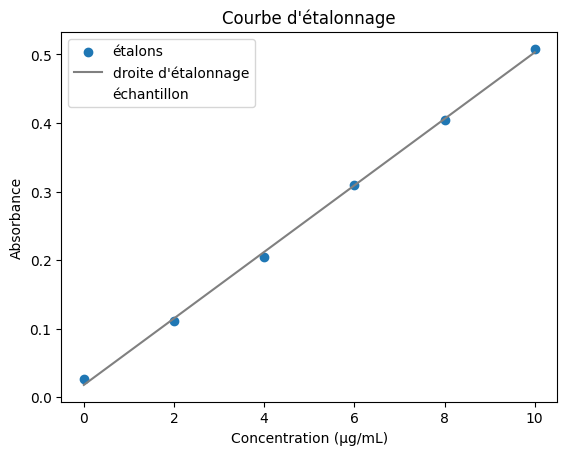

In [4]:
A_inconnu = 0.310
dilution = 5
C_cuvette = (A_inconnu - ordonnee) / pente          # concentration dans la cuvette (µg/mL)
C_mere = C_cuvette * dilution                  # concentration de la solution mère (µg/mL)
print(f"Dans la cuvette : {C_cuvette:.2f} µg/mL | Solution mère : {C_mere:.1f} µg/mL")
# Graphique
plt.scatter(conc, absorbance, label="étalons")
plt.plot(conc, A_calc, color="gray", label="droite d'étalonnage")
# marker: l'étoile s'écrit "*"
plt.scatter(C_cuvette, A_inconnu, marker="", s=200, color="red", label="échantillon")
plt.title("Courbe d'étalonnage")
plt.xlabel("Concentration (µg/mL)")
plt.ylabel("Absorbance")
plt.legend()
plt.show()

Dans la cuvette : 6.02 µg/mL | Solution mère : 30.1 µg/mL


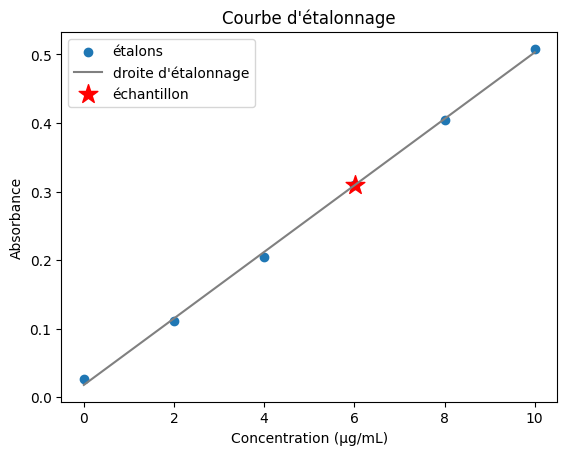

In [5]:
A_inconnu = 0.310
dilution = 5
C_cuvette = (A_inconnu - ordonnee) / pente          # concentration dans la cuvette (µg/mL)
C_mere = C_cuvette * dilution                  # concentration de la solution mère (µg/mL)
print(f"Dans la cuvette : {C_cuvette:.2f} µg/mL | Solution mère : {C_mere:.1f} µg/mL")
# Graphique
plt.scatter(conc, absorbance, label="étalons")
plt.plot(conc, A_calc, color="gray", label="droite d'étalonnage")
# marker: l'étoile s'écrit "*"
plt.scatter(C_cuvette, A_inconnu, marker="*", s=200, color="red", label="échantillon")
plt.title("Courbe d'étalonnage")
plt.xlabel("Concentration (µg/mL)")
plt.ylabel("Absorbance")
plt.legend()
plt.show()

Votre reponse : Q1 = a , Q2 = b , Q3 = a

In [6]:
def michaelis(S, Vmax, Km):
    return Vmax * S / (Km + S)
S = np.array([0.5, 1, 2, 5, 10, 20, 50, 100])                    # mM
# mM, concentration de l'inhibiteur
I = 10
v_sans = (michaelis(S, 120, 8) * np.random.normal(1, 0.04, S.size)).round(1)
v_avec = (michaelis(S, 120, 8 * (1 + I / 5)) * np.random.normal(1, 0.04, S.size)).round(1)
pd.DataFrame({"S (mM)": S, "v sans inhibiteur": v_sans, "v avec inhibiteur": v_avec})

,S (mM),v sans inhibiteur,v avec inhibiteur
0,0.5,7.0,2.6
1,1.0,13.9,4.6
2,2.0,23.0,10.1
3,5.0,45.1,21.5
4,10.0,63.5,34.1
5,20.0,83.4,54.7
6,50.0,102.8,83.0
7,100.0,113.5,102.1


In [7]:
# Sans inhibiteur
param_sans, _ = curve_fit(michaelis, S, v_sans, p0=[100, 5])
Vmax_sans, Km_sans = param_sans
# Avec inhibiteur : même chose avec la deuxième série de vitesses
param_avec, _ = curve_fit(michaelis, S, v_avec, p0=[100, 5])
Vmax_avec, Km_avec = param_avec
pd.DataFrame({"Vmax": [Vmax_sans, Vmax_avec], "Km (mM)": [Km_sans, Km_avec]},
             index=["sans inhibiteur", "avec inhibiteur"]).round(1)

,Vmax,Km (mM)
sans inhibiteur,122.0,8.9
avec inhibiteur,128.9,27.0


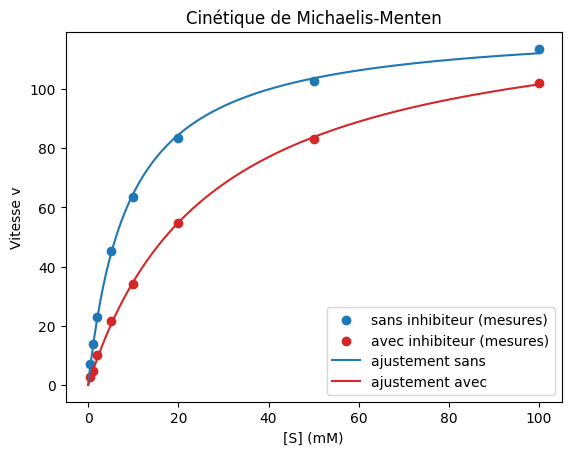

In [8]:
S_fin = np.linspace(0, 100, 300)
plt.scatter(S, v_sans, color="tab:blue", label="sans inhibiteur (mesures)")
plt.scatter(S, v_avec, color="tab:red", label="avec inhibiteur (mesures)")
plt.plot(S_fin, michaelis(S_fin, Vmax_sans, Km_sans), color="tab:blue",
    label="ajustement sans")
plt.plot(S_fin, michaelis(S_fin, Vmax_avec, Km_avec), color="tab:red",
    label="ajustement avec")
plt.title("Cinétique de Michaelis-Menten")
plt.xlabel("[S] (mM)")
plt.ylabel("Vitesse v")
plt.legend()
plt.show()

In [9]:
Ki = I / (Km_avec / Km_sans - 1)
print(f"Ki = {Ki:.1f} mM")

Ki = 4.9 mM


Votre reponse : Q1 = b , Q2 = a , Q3 = a

In [10]:
def hill(logC, Emin, Emax, logEC50, n):
    return Emin + (Emax - Emin) / (1 + 10 ** ((logEC50 - logC) * n))
logC = np.arange(-9, -3.5, 0.5)                              # log10 de la concentration (M)
effet_A = (hill(logC, 2, 98, -7.0, 1.0) + np.random.normal(0, 3, logC.size)).round(1)
effet_B = (hill(logC, 2, 98, -6.3, 1.0) +np.random.normal(0, 3, logC.size)).round(1)
pd.DataFrame({"logC": logC, "effet A (%)": effet_A, "effet B (%)": effet_B})

,logC,effet A (%),effet B (%)
0,-9.0,4.0,2.8
1,-8.5,2.7,2.6
2,-8.0,10.3,5.4
3,-7.5,25.6,5.3
4,-7.0,49.2,19.4
5,-6.5,77.4,39.0
6,-6.0,90.9,64.0
7,-5.5,100.0,86.0
8,-5.0,99.3,93.5
9,-4.5,94.0,98.4


In [11]:
# Compound A
pA, _ = curve_fit(hill, logC, effet_A, p0=[0, 100, -7, 1])
EC50_A = 10 ** pA[2] * 1e9  # in nM

# Compound B
pB, _ = curve_fit(hill, logC, effet_B, p0=[0, 100, -7, 1])
EC50_B = 10 ** pB[2] * 1e9  # in nM

tableau = pd.DataFrame({
    "Emax": [pA[1], pB[1]],
    "pEC50": [-pA[2], -pB[2]],
    "EC50 (nM)": [EC50_A, EC50_B],
    "Hill slope": [pA[3], pB[3]]
}, index=["Compound A", "Compound B"]).round(2)

tableau

,Emax,pEC50,EC50 (nM),Hill slope
Compound A,98.71,7.00,99.71,1.08
Compound B,100.25,6.26,546.22,0.96


 Votre reponse : Q1 = a, Q2 = a, Q3 = a

In [17]:
dose = 500                                                          # mg
t = np.array([0.25, 0.5, 1, 2, 4, 6, 8, 12, 24])                    # h
conc_pl = (12.5 * np.exp(-0.173 * t) * np.random.normal(1, 0.05, t.size)).round(2)    # mg/L
pk = pd.DataFrame({"temps (h)": t, "concentration (mg/L)": conc_pl})
pk

,temps (h),concentration (mg/L)
0,0.25,11.82
1,0.50,10.91
2,1.00,10.94
3,2.00,8.79
4,4.00,6.62
5,6.00,4.45
6,8.00,3.22
7,12.00,1.51
8,24.00,0.19


In [18]:
# Natural logarithm of concentrations
ln_conc = np.log(conc_pl)

# Linear regression of ln(C) vs t
pente_pk, ordonnee_pk = np.polyfit(t, ln_conc, 1)

k = -pente_pk               # elimination rate constant (1/h)
C0 = np.exp(ordonnee_pk)    # initial concentration (mg/L)
t_demi = np.log(2) / k      # half-life (h)
Vd = dose / C0              # volume of distribution (L)

print(f"k = {k:.3f} 1/h | C0 = {C0:.1f} mg/L | t1/2 = {t_demi:.1f} h | Vd = {Vd:.0f} L")

k = 0.175 1/h | C0 = 12.6 mg/L | t1/2 = 4.0 h | Vd = 40 L


In [19]:
temps_97 = 5 * t_demi
print(f"Temps pour éliminer 97 % de la dose : environ {temps_97:.0f} h")

Temps pour éliminer 97 % de la dose : environ 20 h


# Réponse Interprétation : a) alignés sur une droite | a) 1 (exponentielle)

Partie 5 : Conclusion

· Partie 1 : la pente de la droite d'étalonnage est 0.0512, et la solution mère contient 30 µg/mL.
· Partie 2 : l'inhibiteur augmente le Km et ne change pas Vmax : c'est une inhibition compétitive.
· Partie 3 : le composé A est le plus puissant (EC50 = 100 nM).
· Partie 4 : la demi-vie est de 4.0 h et le volume de distribution de 40 L.
· Limites : données simulées, un seul compartiment, modèle simplifié.